# Introduction
Naive Bayes is a classification algorithm which is based on Bayes theorem with strong and naïve independence assumptions. It simplifies learning by assuming that features are independent of given class.This paper surveys about naïve Bayes algorithm, which describes its concept, hidden naïve Bayes, text classification, traditional naïve Bayes and machine learning. Also represents augmented naïve Bayes by examples. And at the end some applications of naïve Bayes and its advantages and disadvantages has discussed for a better understanding of the algorithm.
# Biomechanical Features of Orthopedic Patients

In this project we are provided with multiple instances of orthopedic parameters and we are also provided with their classification as **Normal** or **Abnormal**

![img](https://user-images.githubusercontent.com/67789350/105318173-2d45f880-5be9-11eb-9acf-58bf5d130fbc.png)

To get started , first download the csv file from this [link](https://drive.google.com/file/d/1uPHmxoTvoemq8X54Y5GehYy13_J404Zn/view?usp=sharing)

We have to implement K Nearest Neighbour, the algorithm is used to classify points according to class of their K nearest neighbour point

And also on the the same dataset Implement a Gaussian Naive Bayes based classifier

### Now that you have the dataset , let us get started !



# Section I : Accessing the Data

- Make a pandas DataFrame from the CSV
- How many variables does the dataset contain?
- What is the data about?
- What are we trying to predict here?

- Make a pandas DataFrame from the CSV

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('ortho_knnnb.csv')
df.head()

,pelvic_incidence,pelvic_tilt numeric,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,Abnormal
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,Abnormal
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,Abnormal
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,Abnormal
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,Abnormal


- How many variables does the dataset contain?

In [3]:
print("Number of variables in the dataset : ", df.shape[1],
      "\nThey are : ",df.columns.values)

Number of variables in the dataset :  7 
They are :  ['pelvic_incidence' 'pelvic_tilt numeric' 'lumbar_lordosis_angle'
 'sacral_slope' 'pelvic_radius' 'degree_spondylolisthesis' 'class']


- What is the data about?

The data is of several quantifiable orthopedic parameters of a human subject

- What are we trying to predict here?

The data is the orthopedic medical information of several patient some with abnormalities in their bones and some without and several quantifiable medical parameters that can be used to predict if a new patient might or might not have an orthopedic abnormality.

# Section II : Exploratory Data Analysis

- Perform some descriptive statistics and make a note of your findings 
- Plot appropriate graphs to understand the relation between the variables.
- Point out any observations and comment on the strength of the relationships if any.

- Perform some descriptive statistics and make a note of your findings

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt numeric       310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    object 
dtypes: float64(6), object(1)
memory usage: 17.1+ KB


In [5]:
df.describe()

,pelvic_incidence,pelvic_tilt numeric,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
count,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,60.496653,17.542822,51.930930,42.953831,117.920655,26.296694
std,17.236520,10.008330,18.554064,13.423102,13.317377,37.559027
min,26.147921,-6.554948,14.000000,13.366931,70.082575,-11.058179
25%,46.430294,10.667069,37.000000,33.347122,110.709196,1.603727
50%,58.691038,16.357689,49.562398,42.404912,118.268178,11.767934
75%,72.877696,22.120395,63.000000,52.695888,125.467674,41.287352
max,129.834041,49.431864,125.742385,121.429566,163.071041,418.543082


In [6]:
# Correlation matrix
df_copy = df
df_copy["class"] = [0 if i == "Abnormal" else 1 for i in df_copy["class"]]
corrmat = df_copy.corr()
corrmat

,pelvic_incidence,pelvic_tilt numeric,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
pelvic_incidence,1.000000,0.629199,0.717282,0.814960,-0.247467,0.638743,-0.353336
pelvic_tilt numeric,0.629199,1.000000,0.432764,0.062345,0.032668,0.397862,-0.326063
lumbar_lordosis_angle,0.717282,0.432764,1.000000,0.598387,-0.080344,0.533667,-0.312484
sacral_slope,0.814960,0.062345,0.598387,1.000000,-0.342128,0.523557,-0.210602
pelvic_radius,-0.247467,0.032668,-0.080344,-0.342128,1.000000,-0.026065,0.309857
degree_spondylolisthesis,0.638743,0.397862,0.533667,0.523557,-0.026065,1.000000,-0.443687
class,-0.353336,-0.326063,-0.312484,-0.210602,0.309857,-0.443687,1.000000


In [7]:
corrmat = corrmat['class'][:-1].sort_values(ascending=False)
print(corrmat)

pelvic_radius               0.309857
sacral_slope               -0.210602
lumbar_lordosis_angle      -0.312484
pelvic_tilt numeric        -0.326063
pelvic_incidence           -0.353336
degree_spondylolisthesis   -0.443687
Name: class, dtype: float64


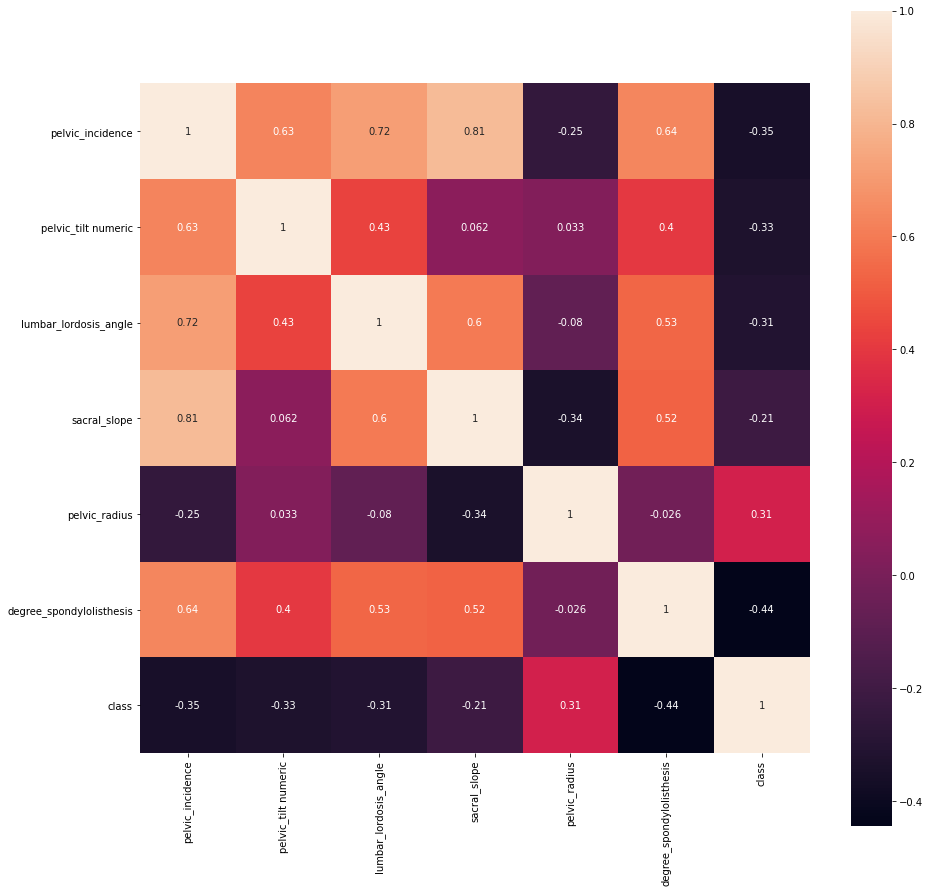

In [8]:
#Correlation map
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(), annot=True,square=True) 
plt.show()

- Plot appropriate graphs to understand the relation between the variables.

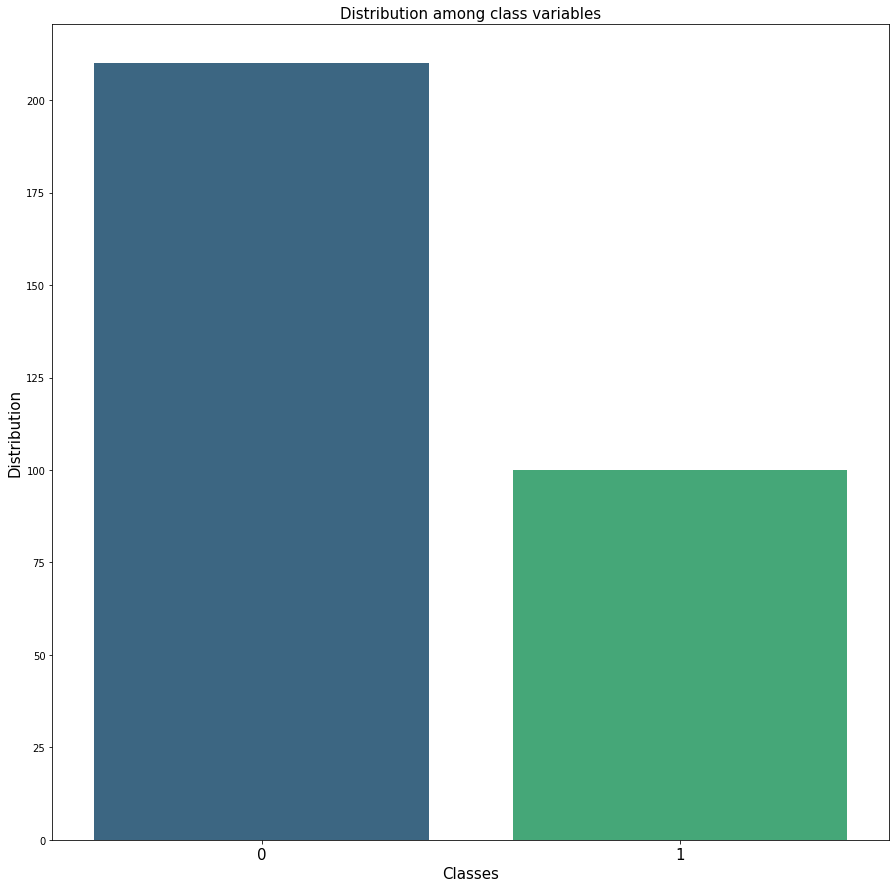

In [9]:
plt.figure(figsize=(15,15))

sns.countplot(x ='class', data = df, palette = 'viridis')

plt.title('Distribution among class variables', fontsize = 15)
plt.xlabel('Classes', fontsize = 15)
plt.ylabel('Distribution', fontsize = 15)
plt.xticks(fontsize = 15)

# Show the plot
plt.show()


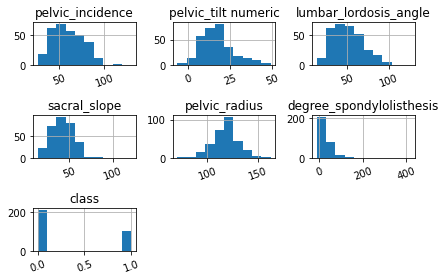

In [10]:
# Histogram shows the distribution of each feature
df.hist(xrot = 20, )
plt.tight_layout()
plt.show()  

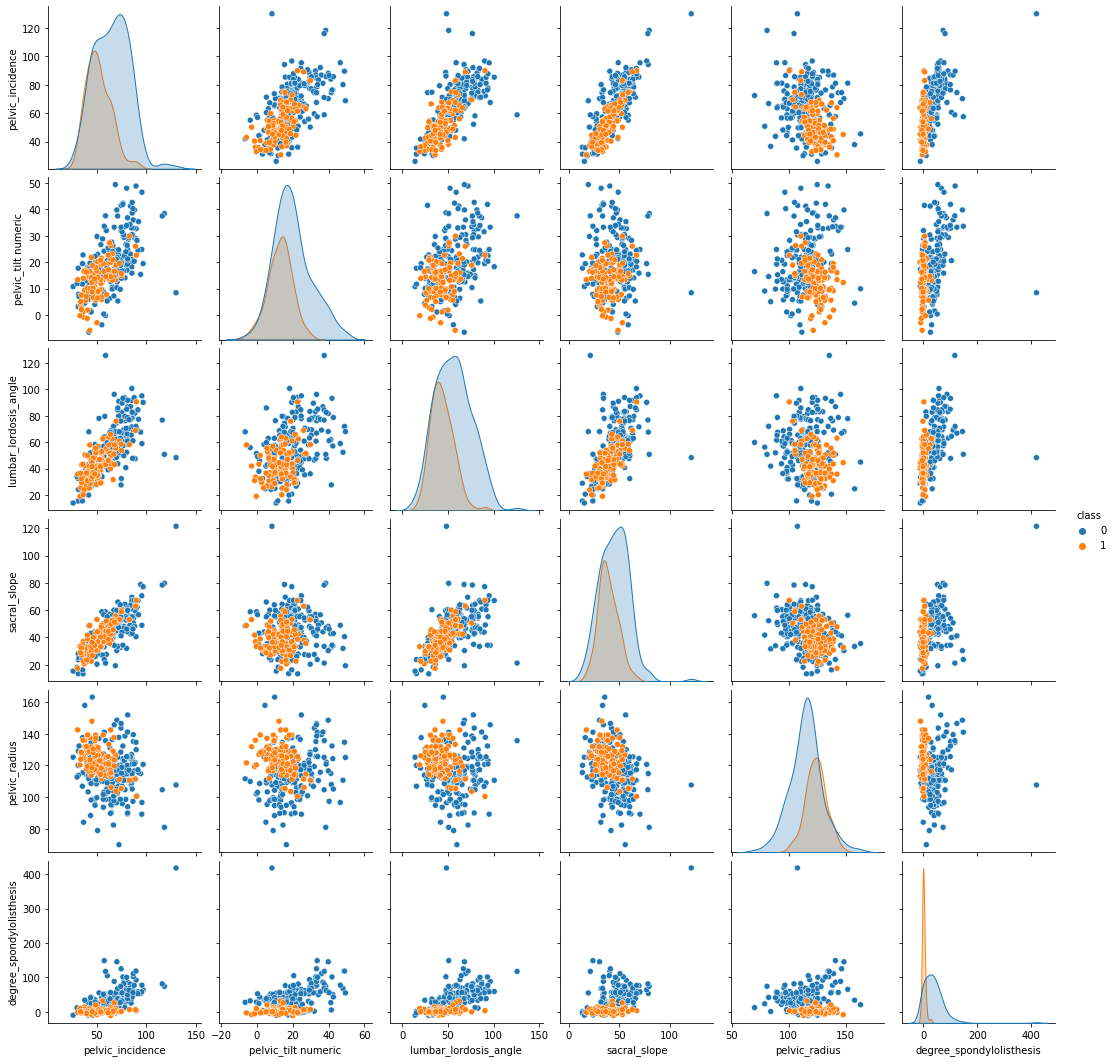

In [11]:
sns.pairplot(data=df, hue="class")
plt.show()

# Section III : Prepare data for Training!

- Make a new column `symptom_class` with the abnormal rows as 1 and the normal rows as 0, drop the `class` column
- Split the entire dataset into independent features and symptoms as the response variable
- Normalize the variables.


- Make a new column `symptom_class` with the abnormal rows as 1 and the normal rows as 0, drop the `class` column

In [12]:
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
df['symptom_class'] = labelencoder.fit_transform(df['class'])

classnames = labelencoder.classes_


In [13]:
data = df.drop(["class"], axis=1)

In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt numeric       310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   symptom_class             310 non-null    int64  
dtypes: float64(6), int64(1)
memory usage: 17.1 KB


- Split the entire dataset into independent features and symptoms as the response variable

In [15]:
X = data.drop(['symptom_class'],axis=1)
y = data['symptom_class']

- Normalize the variables.

In [16]:
X_norm = (X-X.min())/(X.max()-X.min())
y_norm = (y-y.min())/(y.max()-y.min())

# Section IV : Training with KNN

- Use `train_test_split` from `sklearn` and split the parameters and classes into train and test sets
- Starting with **three** nearest neighbours , train your KNN model and make a note of accuracy and other diagnostics for both training and test sets.
- Try with increasing the **k** value and check if there is any improvement in model performance. Use different value to arrive at the optimal value of **k**.
- Evaluate your final model using appropriate metrics for classification and comment on them.

- Use `train_test_split` from `sklearn` and split the parameters and classes into train and test sets

In [17]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X_norm,y_norm, test_size=0.2, random_state=11)

- Starting with **three** nearest neighbours , train your KNN model and make a note of accuracy and other diagnostics for both training and test sets.

In [18]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 3) 
knn.fit(x_train, y_train)
print(" {} nn score: {} ".format(3,knn.score(x_test,y_test)))

 3 nn score: 0.8548387096774194 


In [19]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 5) 
knn.fit(x_train, y_train)
print(" {} nn score: {} ".format(5,knn.score(x_test,y_test)))

 5 nn score: 0.8870967741935484 


- Try with increasing the **k** value and check if there is any improvement in model performance. Use different value to arrive at the optimal value of **k**.

In [20]:
score_list = []
for i in range(1,20):
    knn2 = KNeighborsClassifier(n_neighbors = i)
    knn2.fit(x_train, y_train)
    score_list.append(knn2.score(x_test, y_test))
print(score_list)

[0.9032258064516129, 0.8709677419354839, 0.8548387096774194, 0.8870967741935484, 0.8870967741935484, 0.8548387096774194, 0.8709677419354839, 0.9032258064516129, 0.8870967741935484, 0.8870967741935484, 0.8870967741935484, 0.8870967741935484, 0.8870967741935484, 0.8709677419354839, 0.8387096774193549, 0.8709677419354839, 0.8548387096774194, 0.8709677419354839, 0.8870967741935484]


In [21]:
current_max = score_list[0]
for i in range(len(score_list)):
    if current_max < score_list[i]:
        current_max = score_list[i]
print(current_max)

0.9032258064516129


- Evaluate your final model using appropriate metrics for classification and comment on them.

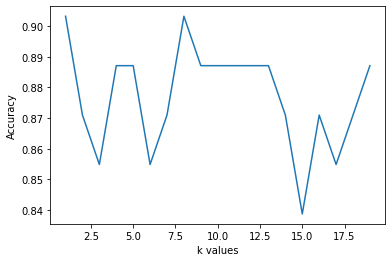

In [22]:
plt.plot(range(1,20),score_list)
plt.xlabel("k values")
plt.ylabel("Accuracy")
plt.show()

In [23]:
knn3 = KNeighborsClassifier(n_neighbors = 8) #k value
knn3.fit(x_train, y_train)
print(" {} nn score: {} ".format(8,knn3.score(x_test,y_test)))

 8 nn score: 0.9032258064516129 


In [24]:
y_pred_knn = knn3.predict(x_test)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_knn)
print("KNN result confusion matrix : \n", cm)

KNN result confusion matrix : 
 [[42  2]
 [ 4 14]]


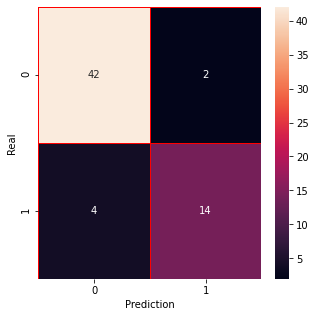

In [25]:
# Confusion matrix
figure, axes = plt.subplots(figsize=(5,5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=axes)
plt.xlabel("Prediction")
plt.ylabel("Real")
plt.show()


# Section V : Training with Naive Bayes

- Now , fit a Naive Bayes Classifier to the same data. 
- Train a NB model with default arguments and make a note of training and test metrics
- What are your inferences on the relative performance between the KNN and NB based models? 
- Which of these models would you recommend and with what reasons ?

- Now , fit a Naive Bayes Classifier to the same data. 

In [26]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(x_train,y_train)
print("test score with naive bayes: ", nb.score(x_test,y_test))


test score with naive bayes:  0.8225806451612904


- Train a NB model with default arguments and make a note of training and test metrics

In [27]:
y_pred_nb = nb.predict(x_test)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_nb)
print("NB result confusion matrix : \n", cm)

NB result confusion matrix : 
 [[34 10]
 [ 1 17]]


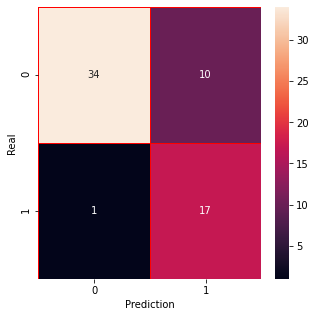

In [28]:
#confusion metrics visualization
f, ax = plt.subplots(figsize=(5,5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("Prediction")
plt.ylabel("Real")
plt.show()


- What are your inferences on the relative performance between the KNN and NB based models? 

- Which of these models would you recommend and with what reasons ?

# Section VI : Wraping it up ! (This is optional but good for... like spinach...)

- Which of these models performed better ? 
- Test these two models on other datasets as well !
  - To get started you could try these on 
    - The IRIS Dataset
    - The Breast Cancer Dataset
- What other datasets these two models would perform well in?

